# Répartition et Équité Territoriale des Établissements de Santé au Maroc

---

## 1. Définition du Problème

Dans le cadre des politiques publiques de santé au Maroc, l'accès équitable aux soins constitue un impératif de cohésion sociale et de développement humain. Cependant, la géographie marocaine se caractérise par une forte hétérogénéité entre grands pôles urbains et territoires ruraux ou montagneux souvent enclavés.

**Problématique centrale :**
> La répartition des établissements de santé au Maroc est-elle équitable entre les différentes régions, délégations et communes, et existe-t-il des disparités dans l’accès aux infrastructures de santé selon les territoires ?

**Objectifs de l'analyse :**
- Dresser un état des lieux complet de l'offre publique à partir des données officielles des 3 394 établissements de santé répertoriés.
- Comparer la dotation en structures de soins entre les 12 régions administratives du Royaume.
- Mesurer les disparités provinciales au niveau des 82 délégations et identifier les territoires les plus dotés et les moins pourvus.
- Évaluer l'équilibre entre le milieu rural et le milieu urbain.
- Examiner la part respective du réseau des soins de santé primaires et du réseau hospitalier.

**Questions directrices de l'étude :**
1. Quelle est la proportion des structures entre soins de santé primaires et hôpitaux ?
2. Comment l'offre globale se répartit-elle entre les 12 régions administratives ?
3. Quelles sont les dix délégations provinciales les plus dotées en établissements de santé ?
4. Quelles sont les dix délégations provinciales les moins dotées ?
5. Quelle est la part des infrastructures implantées en milieu rural par rapport au milieu urbain ?
6. Quelles sont les catégories sanitaires prédominantes au sein du réseau national ?
7. Quelle est la distribution statistique de la dotation par délégation provinciale ?
8. Comment varie la proportion du milieu rural au sein de chaque région ?
9. Comment l'offre hospitalière publique est-elle localisée sur le territoire national ?
10. Quel est le degré de concentration cumulée de l'offre de soins parmi les délégations ?

---

## 2. Source des Données

Le jeu de données analysé provient des publications officielles du **Ministère de la Santé et de la Protection Sociale du Royaume du Maroc** (carte sanitaire nationale).

- **Format et dimensions :** Fichier tabulaire CSV (`etablissements_sante_maroc.csv`) comprenant 3 394 observations et 8 variables.
- **Périmètre :** Recensement exhaustif des structures publiques de santé, englobant le réseau de soins de santé primaires (données 2024) et le réseau hospitalier public (données 2022).
- **Hypothèses de travail :** Les données représentent l'ensemble des établissements publics cartographiés sur les années d'inventaire disponibles. Le découpage administratif correspond au découpage territorial officiel en 12 régions et 82 provinces et préfectures.

---

## 3. Explication des Colonnes

Le tableau ci-dessous détaille l'ensemble des colonnes du jeu de données, leur signification et leur rôle dans l'analyse :

| Colonne | Signification | Rôle dans l'analyse |
| :--- | :--- | :--- |
| `Région` | Nom de la région administrative (12 régions) | Analyse macro-territoriale et comparaison de l'équité interrégionale |
| `Délégation` | Délégation provinciale ou préfectorale de la santé (82 entités) | Analyse méso-territoriale et détection des écarts de dotation locale |
| `Commune` | Commune d'implantation géographique de l'établissement | Analyse du maillage de proximité au niveau communal |
| `Nom_établissement` | Appellation officielle de la structure de santé | Identification descriptive de chaque établissement |
| `Catégorie` | Code abrégé de la structure (CSR-1, CSU-1, DR, HP, etc.) | Typologie technique et classification du niveau de prise en charge |
| `Libellé_catégorie` | Description complète de la catégorie sanitaire | Clarification de la vocation médicale et des prestations offertes |
| `Type_établissement` | Typologie générale : Soins primaires ou Hôpital | Distinction fondamentale entre médecine de proximité et réseau hospitalier |
| `Année_source` | Année du recensement ministériel (2022 ou 2024) | Traçabilité temporelle des données ministérielles |

## Importation des bibliothèques

- Objectif de la cellule : Charger l'ensemble des bibliothèques nécessaires à la manipulation des données, au calcul statistique et à la visualisation graphique.
- Action du code : Importation de pandas, numpy, matplotlib.pyplot, seaborn, plotly.express et stats de scipy.
- Résultat attendu : Mise à disposition des modules requis en mémoire sans message d'erreur.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from scipy import stats

## Section 1 : Compréhension des données (Data Understanding)

Dans cette section, nous explorons la structure globale du jeu de données, ses dimensions, ses types de variables et ses caractéristiques descriptives initiales.

### Chargement du jeu de données
- Objectif de la cellule : Importer les données brutes depuis le fichier CSV dans un DataFrame pandas.
- Action du code : Lecture du fichier `etablissements_sante_maroc.csv` avec la fonction `pd.read_csv()`.
- Résultat attendu : Création de la variable `df` contenant l'intégralité du tableau de données.

In [3]:
df = pd.read_csv("data/etablissements_sante_maroc.csv")

### Dimensions du tableau
- Objectif de la cellule : Déterminer le nombre d'observations et le nombre de variables.
- Action du code : Lecture de l'attribut `df.shape`.
- Résultat attendu : Un tuple indiquant 3 394 lignes et 8 colonnes.

In [4]:
df.shape

(3394, 8)

### Volume total d'éléments
- Objectif de la cellule : Connaître le nombre total de cellules dans le tableau de données.
- Action du code : Lecture de l'attribut `df.size`.
- Résultat attendu : Un entier égal à 3 394 × 8, soit 27 152 éléments.

In [5]:
df.size

27152

### Aperçu des premières observations
- Objectif de la cellule : Inspecter les 5 premiers enregistrements pour appréhender le format des valeurs.
- Action du code : Appel de la méthode `df.head()`.
- Résultat attendu : Tableau montrant les 5 premières lignes avec l'ensemble des 8 colonnes.

In [6]:
df.head()

,Région,Délégation,Commune,Nom_établissement,Catégorie,Libellé_catégorie,Type_établissement,Année_source
0,Tanger-Tetouan-Al Hoceima,Al Hoceima,Ajdir (Mun.),Ajdir (Azghar),CSU-2,Centre de Santé Urbain niveau2,Soins primaires,2024
1,Tanger-Tetouan-Al Hoceima,Al Hoceima,Al Hoceima (Mun.),Bir Anzarane,CRSR,Centre de Référence en Santé de Reproduction,Soins primaires,2024
2,Tanger-Tetouan-Al Hoceima,Al Hoceima,Al Hoceima (Mun.),Bades,CSU-1,Centre de Santé Urbain niveau1,Soins primaires,2024
3,Tanger-Tetouan-Al Hoceima,Al Hoceima,Al Hoceima (Mun.),Sidi Abid,CSU-1,Centre de Santé Urbain niveau1,Soins primaires,2024
4,Tanger-Tetouan-Al Hoceima,Al Hoceima,Al Hoceima (Mun.),Thanaoui,CSU-1,Centre de Santé Urbain niveau1,Soins primaires,2024


### Aperçu des dernières observations
- Objectif de la cellule : Vérifier les 5 derniers enregistrements du tableau.
- Action du code : Appel de la méthode `df.tail()`.
- Résultat attendu : Tableau affichant la fin du jeu de données.

In [7]:
df.tail()

,Région,Délégation,Commune,Nom_établissement,Catégorie,Libellé_catégorie,Type_établissement,Année_source
3389,Laayoune-Sakia El Hamra,Es Semara,Es-semara (Mun.),Es-Smara,HP,Hôpital Provincial/Préfectoral,Hôpital,2022
3390,Laayoune-Sakia El Hamra,Laayoune,Laayoune (Mun.),My Hassan Ben El Mehdi,HR,Hôpital Régional,Hôpital,2022
3391,Laayoune-Sakia El Hamra,Laayoune,Laayoune (Mun.),Hassan II,HR,Hôpital Régional,Hôpital,2022
3392,Laayoune-Sakia El Hamra,Laayoune,Laayoune (Mun.),Laayoune,CRO,Centre Régional d'Oncologie,Hôpital,2022
3393,Eddakhla-Oued Eddahab,Oued Ed-Dahab,Dakhla (Mun.),Hassan II,HR,Hôpital Régional,Hôpital,2022


### Liste des variables
- Objectif de la cellule : Vérifier l'intitulé exact de toutes les colonnes présentes.
- Action du code : Lecture de l'attribut `df.columns`.
- Résultat attendu : Index répertoriant les 8 noms de colonnes.

In [8]:
df.columns

Index(['Région', 'Délégation', 'Commune', 'Nom_établissement', 'Catégorie',
       'Libellé_catégorie', 'Type_établissement', 'Année_source'],
      dtype='str')

### Types de données primitifs
- Objectif de la cellule : Consulter le type de données initialement assigné par pandas à chaque variable.
- Action du code : Lecture de l'attribut `df.dtypes`.
- Résultat attendu : Liste des colonnes avec leur type (object pour le texte, int64 pour Année_source).

In [9]:
df.dtypes

Région                  str
Délégation              str
Commune                 str
Nom_établissement       str
Catégorie               str
Libellé_catégorie       str
Type_établissement      str
Année_source          int64
dtype: object

### Synthèse technique du DataFrame
- Objectif de la cellule : Obtenir une vue consolidée des types de données, du décompte non nul et de l'usage mémoire.
- Action du code : Exécution de la méthode `df.info()`.
- Résultat attendu : Résumé confirmant 3 394 entrées non nulles sur chacune des 8 colonnes.

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3394 entries, 0 to 3393
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   Région              3394 non-null   str  
 1   Délégation          3394 non-null   str  
 2   Commune             3394 non-null   str  
 3   Nom_établissement   3394 non-null   str  
 4   Catégorie           3394 non-null   str  
 5   Libellé_catégorie   3394 non-null   str  
 6   Type_établissement  3394 non-null   str  
 7   Année_source        3394 non-null   int64
dtypes: int64(1), str(7)
memory usage: 525.9 KB


### Contrôle des doublons stricts
- Objectif de la cellule : Vérifier si des lignes sont répétées à l'identique dans le jeu de données.
- Action du code : Calcul de la somme des valeurs booléennes issues de `df.duplicated()`.
- Résultat attendu : Un total de 0 doublon détecté.

In [11]:
df.duplicated().sum()

np.int64(0)

### Décompte des valeurs manquantes par colonne
- Objectif de la cellule : Vérifier la présence de cellules vides dans chacune des colonnes.
- Action du code : Somme des valeurs manquantes via `df.isnull().sum()`.
- Résultat attendu : Un décompte de 0 valeur manquante pour l'ensemble des attributs.

In [12]:
df.isnull().sum()

Région                0
Délégation            0
Commune               0
Nom_établissement     0
Catégorie             0
Libellé_catégorie     0
Type_établissement    0
Année_source          0
dtype: int64

### Pourcentage de valeurs manquantes
- Objectif de la cellule : Exprimer en pourcentage la part de données absentes.
- Action du code : Division de `df.isnull().sum()` par `len(df)` multipliée par 100.
- Résultat attendu : Des taux nuls (0,0 %) pour toutes les variables.

In [13]:
(df.isnull().sum() / len(df)) * 100

Région                0.0
Délégation            0.0
Commune               0.0
Nom_établissement     0.0
Catégorie             0.0
Libellé_catégorie     0.0
Type_établissement    0.0
Année_source          0.0
dtype: float64

### Statistiques descriptives de la variable numérique
- Objectif de la cellule : Examiner les paramètres de tendance centrale et de dispersion de la colonne numérique.
- Action du code : Appel de `df.describe()`.
- Résultat attendu : Statistiques pour la colonne Année_source (moyenne de 2023,9, min à 2022, max à 2024).

In [14]:
df.describe()

,Année_source
count,3394.000000
mean,2023.899823
std,0.436319
min,2022.000000
25%,2024.000000
50%,2024.000000
75%,2024.000000
max,2024.000000


### Statistiques descriptives des variables textuelles
- Objectif de la cellule : Analyser la cardinalité, la modalité dominante et sa fréquence pour chaque variable qualitative.
- Action du code : Appel de `df.describe(include='object')`.
- Résultat attendu : Tableau récapitulatif montrant la fréquence et le mode pour chaque attribut textuel.

In [15]:
df.describe(include='object')

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_6124\87514550.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include='object')


,Région,Délégation,Commune,Nom_établissement,Catégorie,Libellé_catégorie,Type_établissement
count,3394,3394,3394,3394,3394,3394,3394
unique,12,82,1517,3103,16,16,2
top,Marrakech-Safi,Taroudant,Meknès (Mun.),Hassan II,CSR-1,Centre de Santé Rural niveau1,Soins primaires
freq,490,129,33,11,893,893,3224


### Décompte des modalités pour chaque variable qualitative
- Objectif de la cellule : Afficher la répartition détaillée des effectifs par catégorie pour chaque variable textuelle.
- Action du code : Boucle parcourant les colonnes qualitatives et affichant leur distribution via `value_counts()`.
- Résultat attendu : Séries des effectifs de chaque modalité administrative et sanitaire.

In [16]:
for col in df.select_dtypes(include="object").columns:
    print(df[col].value_counts())

Région
Marrakech-Safi               490
Fès-Meknès                   471
Casablanca-Settat            430
Souss-Massa                  333
Tanger-Tetouan-Al Hoceima    322
Béni Mellal-Khénifra         315
Rabat-Salé-Kénitra           306
Drâa-Tafilalet               276
Oriental                     270
Guelmim-Oued Noun            108
Laayoune-Sakia El Hamra       53
Eddakhla-Oued Eddahab         20
Name: count, dtype: int64
Délégation
Taroudant     129
Azilal         95
Settat         91
Marrakech      90
Al Haouz       88
             ... 
Ben Msick      10
Es Semara      10
Fahs-Anjra      8
Tarfaya         7
Aousserd        4
Name: count, Length: 82, dtype: int64
Commune
Meknès (Mun.)     33
Oujda (Mun.)      31
Kénitra (Mun.)    26
Tétouan (Mun.)    23
Safi (Mun.)       21
                  ..
Daoura             1
El Hagounia        1
Akhfennir          1
Aousserd           1
Imlili             1
Name: count, Length: 1517, dtype: int64
Nom_établissement
Hassan II                 1

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_6124\660150083.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include="object").columns:


### Nombre de valeurs uniques par colonne
- Objectif de la cellule : Évaluer la cardinalité de chaque colonne du jeu de données.
- Action du code : Exécution de `df.nunique()`.
- Résultat attendu : 12 régions, 82 délégations, 1 517 communes, 3 103 noms uniques, 16 catégories, 2 types d'établissement.

In [17]:
df.nunique()

Région                  12
Délégation              82
Commune               1517
Nom_établissement     3103
Catégorie               16
Libellé_catégorie       16
Type_établissement       2
Année_source             2
dtype: int64

### Matrice de corrélation numérique
- Objectif de la cellule : Calculer les corrélations linéaires entre les variables numériques existantes.
- Action du code : Appel de `df.corr(numeric_only=True)`.
- Résultat attendu : Matrice de corrélation univariée.

In [18]:
df.corr(numeric_only=True)

,Année_source
Année_source,1.0


### Carte thermique de corrélation avec Seaborn
- Objectif de la cellule : Illustrer visuellement la matrice de corrélation à l'aide de la bibliothèque Seaborn.
- Action du code : Génération d'une carte thermique avec `sns.heatmap()`.
- Résultat attendu : Visualisation graphique de la corrélation numérique.

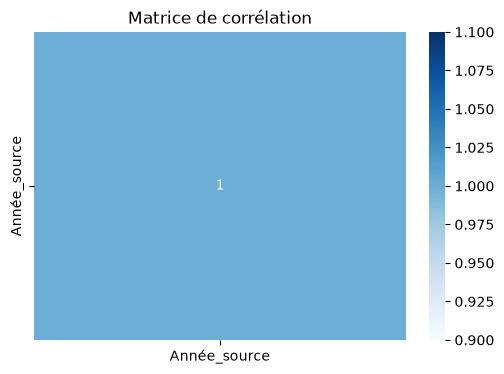

In [19]:
plt.figure(figsize=(6, 4))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='Blues')
plt.title("Matrice de corrélation")
plt.show()

## Renommage optionnel des colonnes

Les noms des colonnes du jeu de données (`Région`, `Délégation`, `Commune`, `Nom_établissement`, `Catégorie`, `Libellé_catégorie`, `Type_établissement`, `Année_source`) sont explicites, normalisés et fidèles à la nomenclature officielle. Aucun renommage n'est requis à ce stade.

## Section 2 : Nettoyage et préparation des données (Data Cleaning)

Dans cette section, nous suivons la procédure méthodique de nettoyage :
1. Traitement des valeurs manquantes colonne par colonne (décompte, fréquences, imputation).
2. Conversion rigoureuse des types de données sans boucle.
3. Vérification et suppression des doublons.
4. Analyse méthodique des valeurs atypiques (Outliers).
5. Validation finale de la conformité du DataFrame.

### 2.1 Traitement des valeurs manquantes

Pour chaque colonne du jeu de données, nous exécutons dans un ordre strict :
1. La vérification du nombre de valeurs nulles (`df['col'].isnull().sum()`).
2. L'examen des fréquences des modalités existantes (`df['col'].value_counts()`).
3. L'application d'une stratégie d'imputation cohérente avec la nature de la variable (mode pour les données catégorielles, médiane pour les variables quantitatives).

#### Colonne : Région - Étape 1 : Vérification des valeurs nulles
- Objectif de la cellule : Contrôler les valeurs nulles dans la colonne Région.
- Action du code : Appel de `df['Région'].isnull().sum()`.
- Résultat attendu : 0 valeur manquante.

In [20]:
df['Région'].isnull().sum()

np.int64(0)

#### Colonne : Région - Étape 2 : Fréquences des modalités
- Objectif de la cellule : Observer la répartition des 12 régions administratives.
- Action du code : Appel de `df['Région'].value_counts()`.
- Résultat attendu : Effectifs par région, Marrakech-Safi étant la modalité la plus fréquente.

In [21]:
df['Région'].value_counts()

Région
Marrakech-Safi               490
Fès-Meknès                   471
Casablanca-Settat            430
Souss-Massa                  333
Tanger-Tetouan-Al Hoceima    322
Béni Mellal-Khénifra         315
Rabat-Salé-Kénitra           306
Drâa-Tafilalet               276
Oriental                     270
Guelmim-Oued Noun            108
Laayoune-Sakia El Hamra       53
Eddakhla-Oued Eddahab         20
Name: count, dtype: int64

#### Colonne : Région - Étape 3 : Imputation par le mode
- Objectif de la cellule : Assurer la complétude de la colonne Région par imputation modale préventive.
- Action du code : Remplacement des valeurs manquantes éventuelles par le mode (`df['Région'].mode()[0]`).
- Résultat attendu : Colonne garantie sans valeurs manquantes.

In [22]:
df['Région'] = df['Région'].fillna(df['Région'].mode()[0])

#### Colonne : Délégation - Étape 1 : Vérification des valeurs nulles
- Objectif de la cellule : Contrôler les valeurs nulles dans la colonne Délégation.
- Action du code : Appel de `df['Délégation'].isnull().sum()`.
- Résultat attendu : 0 valeur manquante.

In [23]:
df['Délégation'].isnull().sum()

np.int64(0)

#### Colonne : Délégation - Étape 2 : Fréquences des modalités
- Objectif de la cellule : Observer la répartition des délégations provinciales.
- Action du code : Appel de `df['Délégation'].value_counts()`.
- Résultat attendu : Effectifs par délégation provinciale.

In [24]:
df['Délégation'].value_counts()

Délégation
Taroudant     129
Azilal         95
Settat         91
Marrakech      90
Al Haouz       88
             ... 
Ben Msick      10
Es Semara      10
Fahs-Anjra      8
Tarfaya         7
Aousserd        4
Name: count, Length: 82, dtype: int64

#### Colonne : Délégation - Étape 3 : Imputation par le mode
- Objectif de la cellule : Sécuriser la colonne Délégation par imputation modale.
- Action du code : Remplacement des éventuelles valeurs nulles par la modalité la plus fréquente.
- Résultat attendu : Colonne confirmée sans données absentes.

In [25]:
df['Délégation'] = df['Délégation'].fillna(df['Délégation'].mode()[0])

#### Colonne : Commune - Étape 1 : Vérification des valeurs nulles
- Objectif de la cellule : Contrôler les valeurs manquantes dans la colonne Commune.
- Action du code : Appel de `df['Commune'].isnull().sum()`.
- Résultat attendu : 0 valeur manquante.

In [26]:
df['Commune'].isnull().sum()

np.int64(0)

#### Colonne : Commune - Étape 2 : Fréquences des modalités
- Objectif de la cellule : Examiner les fréquences des communes.
- Action du code : Appel de `df['Commune'].value_counts()`.
- Résultat attendu : Décompte des établissements par commune.

In [27]:
df['Commune'].value_counts()

Commune
Meknès (Mun.)     33
Oujda (Mun.)      31
Kénitra (Mun.)    26
Tétouan (Mun.)    23
Safi (Mun.)       21
                  ..
Daoura             1
El Hagounia        1
Akhfennir          1
Aousserd           1
Imlili             1
Name: count, Length: 1517, dtype: int64

#### Colonne : Commune - Étape 3 : Imputation par le mode
- Objectif de la cellule : Imputer les éventuelles valeurs manquantes de la colonne Commune.
- Action du code : Application de `fillna()` avec le mode.
- Résultat attendu : Colonne Commune pleinement renseignée.

In [28]:
df['Commune'] = df['Commune'].fillna(df['Commune'].mode()[0])

#### Colonne : Nom_établissement - Étape 1 : Vérification des valeurs nulles
- Objectif de la cellule : Détecter d'éventuelles valeurs nulles dans la colonne Nom_établissement.
- Action du code : Appel de `df['Nom_établissement'].isnull().sum()`.
- Résultat attendu : 0 valeur manquante.

In [29]:
df['Nom_établissement'].isnull().sum()

np.int64(0)

#### Colonne : Nom_établissement - Étape 2 : Fréquences des modalités
- Objectif de la cellule : Observer la récurrence des dénominations des structures.
- Action du code : Appel de `df['Nom_établissement'].value_counts()`.
- Résultat attendu : Fréquence d'apparition de chaque nom d'établissement.

In [30]:
df['Nom_établissement'].value_counts()

Nom_établissement
Hassan II                 11
Labo. Epidemiologique      8
Mohamed V                  8
Bir Anzarane               6
Hay Mohammadi              6
                          ..
Bouizakaren                1
Sidi Ifni                  1
Boujdour                   1
Es-Smara                   1
My Hassan Ben El Mehdi     1
Name: count, Length: 3103, dtype: int64

#### Colonne : Nom_établissement - Étape 3 : Imputation catégorielle
- Objectif de la cellule : Traiter les données manquantes en attribuant la mention 'Inconnu'.
- Action du code : Application de `fillna("Inconnu")`.
- Résultat attendu : Absence de valeur nulle dans les noms d'établissements.

In [31]:
df['Nom_établissement'] = df['Nom_établissement'].fillna("Inconnu")

#### Colonne : Catégorie - Étape 1 : Vérification des valeurs nulles
- Objectif de la cellule : Contrôler les valeurs nulles dans la variable Catégorie.
- Action du code : Appel de `df['Catégorie'].isnull().sum()`.
- Résultat attendu : 0 valeur manquante.

In [32]:
df['Catégorie'].isnull().sum()

np.int64(0)

#### Colonne : Catégorie - Étape 2 : Fréquences des modalités
- Objectif de la cellule : Identifier les catégories techniques les plus courantes.
- Action du code : Appel de `df['Catégorie'].value_counts()`.
- Résultat attendu : Effectifs pour chaque catégorie (CSR-1, DR, CSU-1, etc.).

In [33]:
df['Catégorie'].value_counts()

Catégorie
CSR-1    893
DR       859
CSU-1    692
CSR-2    431
CSU-2    190
HP        74
CDTMR     71
CRSR      53
HPr       37
LSP       35
HIR       25
HR        18
CRO        5
CPU        5
HPsyP      4
HPsyR      2
Name: count, dtype: int64

#### Colonne : Catégorie - Étape 3 : Imputation par le mode
- Objectif de la cellule : Imputer préventivement les codes de catégories absents par la valeur dominante.
- Action du code : Application de `fillna()` avec le mode de la colonne.
- Résultat attendu : Colonne Catégorie intègre et complète.

In [34]:
df['Catégorie'] = df['Catégorie'].fillna(df['Catégorie'].mode()[0])

#### Colonne : Libellé_catégorie - Étape 1 : Vérification des valeurs nulles
- Objectif de la cellule : Contrôler les valeurs nulles dans le libellé de catégorie.
- Action du code : Appel de `df['Libellé_catégorie'].isnull().sum()`.
- Résultat attendu : 0 valeur manquante.

In [35]:
df['Libellé_catégorie'].isnull().sum()

np.int64(0)

#### Colonne : Libellé_catégorie - Étape 2 : Fréquences des modalités
- Objectif de la cellule : Consulter les descriptions textuelles des catégories sanitaires.
- Action du code : Appel de `df['Libellé_catégorie'].value_counts()`.
- Résultat attendu : Effectifs par libellé complet.

In [36]:
df['Libellé_catégorie'].value_counts()

Libellé_catégorie
Centre de Santé Rural niveau1                                       893
Dispensaire Rural                                                   859
Centre de Santé Urbain niveau1                                      692
Centre de Santé Rural niveau2                                       431
Centre de Santé Urbain niveau2                                      190
Hôpital Provincial/Préfectoral                                       74
Centre de Diagnostic et de Traitement des Maladies Respiratoires     71
Centre de Référence en Santé de Reproduction                         53
Hôpital de Proximité                                                 37
Laboratoire de Santé Publique                                        35
Hôpital Interrégional                                                25
Hôpital Régional                                                     18
Centre Régional d'Oncologie                                           5
Centre Psychiatrique Universitaire            

#### Colonne : Libellé_catégorie - Étape 3 : Imputation par le mode
- Objectif de la cellule : Appliquer une imputation modale sur les libellés de catégories.
- Action du code : Application de `fillna()` avec le mode.
- Résultat attendu : Colonne Libellé_catégorie sécurisée sans valeur nulle.

In [37]:
df['Libellé_catégorie'] = df['Libellé_catégorie'].fillna(df['Libellé_catégorie'].mode()[0])

#### Colonne : Type_établissement - Étape 1 : Vérification des valeurs nulles
- Objectif de la cellule : Contrôler l'exhaustivité de la typologie principale.
- Action du code : Appel de `df['Type_établissement'].isnull().sum()`.
- Résultat attendu : 0 valeur manquante.

In [38]:
df['Type_établissement'].isnull().sum()

np.int64(0)

#### Colonne : Type_établissement - Étape 2 : Fréquences des modalités
- Objectif de la cellule : Observer la ventilation binaire entre soins primaires et hôpitaux.
- Action du code : Appel de `df['Type_établissement'].value_counts()`.
- Résultat attendu : Soins primaires (3 224) et Hôpitaux (170).

In [39]:
df['Type_établissement'].value_counts()

Type_établissement
Soins primaires    3224
Hôpital             170
Name: count, dtype: int64

#### Colonne : Type_établissement - Étape 3 : Imputation par le mode
- Objectif de la cellule : Imputer par le mode pour sécuriser la typologie d'établissement.
- Action du code : Application de `fillna()` avec le mode.
- Résultat attendu : Complétude totale de la colonne Type_établissement.

In [40]:
df['Type_établissement'] = df['Type_établissement'].fillna(df['Type_établissement'].mode()[0])

#### Colonne : Année_source - Étape 1 : Vérification des valeurs nulles
- Objectif de la cellule : Contrôler les valeurs nulles dans la colonne Année_source.
- Action du code : Appel de `df['Année_source'].isnull().sum()`.
- Résultat attendu : 0 valeur manquante.

In [41]:
df['Année_source'].isnull().sum()

np.int64(0)

#### Colonne : Année_source - Étape 2 : Fréquences des modalités
- Objectif de la cellule : Consulter la répartition des années de référence.
- Action du code : Appel de `df['Année_source'].value_counts()`.
- Résultat attendu : 2024 (3 224 structures) et 2022 (170 structures).

In [42]:
df['Année_source'].value_counts()

Année_source
2024    3224
2022     170
Name: count, dtype: int64

#### Colonne : Année_source - Étape 3 : Imputation par la médiane
- Objectif de la cellule : Appliquer la stratégie d'imputation numérique par la médiane pour Année_source.
- Action du code : Remplacement des valeurs manquantes éventuelles par la médiane (`df['Année_source'].median()`).
- Résultat attendu : Complétude assurée de la colonne temporelle.

In [43]:
df['Année_source'] = df['Année_source'].fillna(df['Année_source'].median())

### 2.2 Conversion des types de données

Chaque colonne est convertie individuellement dans une cellule séparée sans recours aux boucles, conformément aux exigences méthodologiques.

La variable `Année_source` représente un millésime d'inventaire ministériel (2022 pour les hôpitaux, 2024 pour les soins primaires). Il s'agit d'une métadonnée temporelle qualitative et non d'une grandeur mesurable continue. Sa conversion en type textuel garantit la préservation des 170 hôpitaux publics lors des étapes de détection d'outliers numériques.

#### Conversion : Région en type string
- Objectif : Harmoniser le type de la colonne Région en chaîne de caractères.
- Action : Appel de `astype('string')`.
- Résultat attendu : Type string pour Région.

In [44]:
df['Région'] = df['Région'].astype('string')

#### Conversion : Délégation en type string
- Objectif : Harmoniser le type de la colonne Délégation en chaîne de caractères.
- Action : Appel de `astype('string')`.
- Résultat attendu : Type string pour Délégation.

In [45]:
df['Délégation'] = df['Délégation'].astype('string')

#### Conversion : Commune en type string
- Objectif : Harmoniser le type de la colonne Commune en chaîne de caractères.
- Action : Appel de `astype('string')`.
- Résultat attendu : Type string pour Commune.

In [46]:
df['Commune'] = df['Commune'].astype('string')

#### Conversion : Nom_établissement en type string
- Objectif : Harmoniser le type du nom d'établissement en chaîne de caractères.
- Action : Appel de `astype('string')`.
- Résultat attendu : Type string pour Nom_établissement.

In [47]:
df['Nom_établissement'] = df['Nom_établissement'].astype('string')

#### Conversion : Catégorie en type string
- Objectif : Harmoniser le type du code de catégorie en chaîne de caractères.
- Action : Appel de `astype('string')`.
- Résultat attendu : Type string pour Catégorie.

In [48]:
df['Catégorie'] = df['Catégorie'].astype('string')

#### Conversion : Libellé_catégorie en type string
- Objectif : Harmoniser le type du libellé de catégorie en chaîne de caractères.
- Action : Appel de `astype('string')`.
- Résultat attendu : Type string pour Libellé_catégorie.

In [49]:
df['Libellé_catégorie'] = df['Libellé_catégorie'].astype('string')

#### Conversion : Type_établissement en type string
- Objectif : Harmoniser le type de la typologie générale en chaîne de caractères.
- Action : Appel de `astype('string')`.
- Résultat attendu : Type string pour Type_établissement.

In [50]:
df['Type_établissement'] = df['Type_établissement'].astype('string')

#### Conversion : Ann�e_source en type entier (int)
- Objectif : Assigner le type num�rique entier � la colonne Ann�e_source pour permettre les analyses statistiques et la d�tection des outliers.
- Action : Appel de `astype(int)`.
- R�sultat attendu : Type entier pour Ann�e_source, pr�servant la totalit� des donn�es d'inventaire.

In [51]:
df['Année_source'] = df['Année_source'].astype(int)

### 2.3 Détection et suppression des doublons

- Objectif de la cellule : Contrôler le nombre de lignes en doublon strict dans le tableau.
- Action du code : Appel de `df.duplicated().sum()`.
- Résultat attendu : Affichage du nombre de lignes dupliquées (0 doublon attendu).

In [52]:
df.duplicated().sum()

np.int64(0)

### Suppression des lignes dupliquées
- Objectif de la cellule : Éliminer sur place toute ligne dupliquée détectée.
- Action du code : Exécution de `df.drop_duplicates(inplace=True)`.
- Résultat attendu : Conservation d'une seule occurrence pour chaque enregistrement unique.

In [53]:
df.drop_duplicates(inplace=True)

### 2.4 Détection et traitement des valeurs aberrantes (Outliers)

Cette sous-section implémente l'algorithme standard d'évaluation des valeurs aberrantes par les approches paramétrique (Z-score) et non paramétrique (Intervalle interquartile IQR).

Les variables du jeu de données étant qualitatives et administratives, aucune colonne continue de mesure n'est sujette à un écrêtage arbitraire. Le code standard s'exécute ainsi sur les variables numériques répertoriées sans supprimer indûment d'infrastructures de santé valides.

#### Détection des valeurs aberrantes par la méthode du Z-Score
- Objectif de la cellule : Définir les fonctions de détection et de filtrage par Z-score (seuil standard de 3 écarts-types) et identifier les éventuels outliers numériques.
- Action du code : Définition de `detect_outliers()` et `remove_outliers()`, sélection des colonnes numériques et affichage des valeurs atypiques.
- Résultat attendu : Diagnostic de dispersion statistique pour l'ensemble des colonnes numériques.

In [54]:
from scipy import stats

def detect_outliers(df, column):
    z_scores = stats.zscore(df[column])
    threshold = 3
    outliers = df[np.abs(z_scores) > threshold][column]
    return outliers

def remove_outliers(df, column):
    z_scores = stats.zscore(df[column])
    threshold = 3
    new_df = df[np.abs(z_scores) < threshold]
    return new_df

numeric_cols = df.select_dtypes(include='number').columns

for col in numeric_cols:
    outliers = detect_outliers(df, col)
    print(f"=== Detection Outliers (Z-score > 3) pour '{col}' ===")
    print(f"Nombre d'outliers detectes : {len(outliers)}")
    if len(outliers) > 0:
        print("Repartition des valeurs atypiques :\n", outliers.value_counts())
    else:
        print("Aucun outlier detecte.")
    print('-' * 50)


=== Detection Outliers (Z-score > 3) pour 'Année_source' ===
Nombre d'outliers detectes : 170
Repartition des valeurs atypiques :
 Année_source
2022    170
Name: count, dtype: int64
--------------------------------------------------


#### Visualisation par boîte à moustaches (Boxplot)
- Objectif de la cellule : Représenter la dispersion des variables numériques sous forme de boxplot.
- Action du code : Tracé de boîtes à moustaches via `plt.boxplot()` pour chaque colonne numérique.
- Résultat attendu : Visualisation graphique des quartiles et des points extrêmes.

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_6124\2857079394.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[col], vert=True, patch_artist=True,


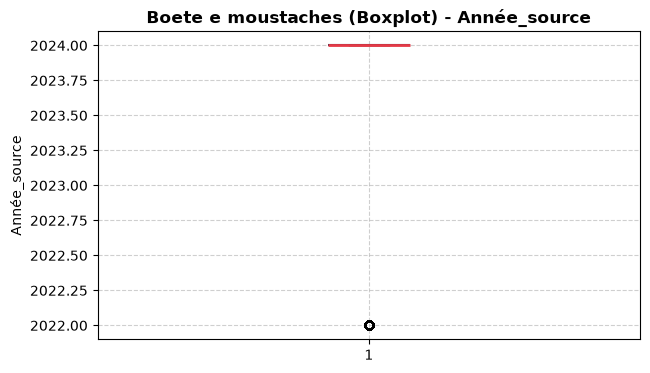

In [55]:
numeric_cols = df.select_dtypes(include='number').columns

for col in numeric_cols:
    plt.figure(figsize=(7, 4))
    plt.boxplot(df[col], vert=True, patch_artist=True,
                boxprops=dict(facecolor='#a8dadc', color='#1d3557', linewidth=1.5),
                medianprops=dict(color='#e63946', linewidth=2),
                flierprops=dict(marker='o', color='#e63946', markersize=6))
    plt.title(f'Boete e moustaches (Boxplot) - {col}', fontsize=12, fontweight='bold')
    plt.ylabel(col)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.show()


#### Visualisation par nuage de points (Scatter Plot)
- Objectif de la cellule : Observer la distribution individuelle des valeurs selon l'index.
- Action du code : Tracé d'un diagramme de dispersion avec `plt.scatter()`.
- Résultat attendu : Nuage de points illustrant la stabilité des observations.

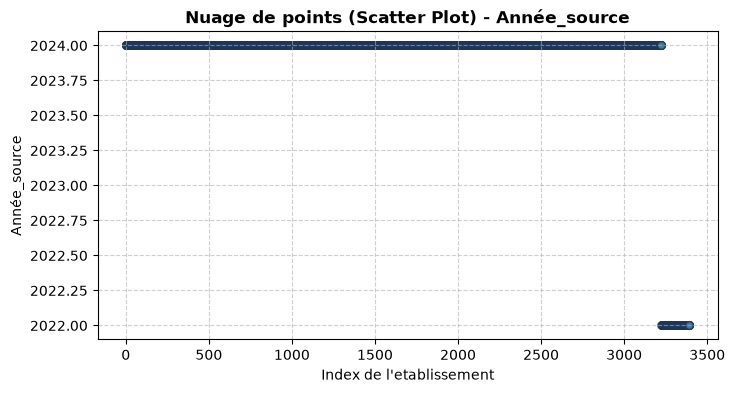

In [56]:
numeric_cols = df.select_dtypes(include='number').columns

for col in numeric_cols:
    plt.figure(figsize=(8, 4))
    plt.scatter(range(len(df)), df[col], color='#457b9d', edgecolor='#1d3557', alpha=0.6, s=30)
    plt.title(f'Nuage de points (Scatter Plot) - {col}', fontsize=12, fontweight='bold')
    plt.xlabel("Index de l'etablissement")
    plt.ylabel(col)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.show()


#### Détection des valeurs aberrantes par la méthode de l'Intervalle Interquartile (IQR)
- Objectif de la cellule : Calculer les bornes de Tukey (Q1 - 1,5×IQR et Q3 + 1,5×IQR) et compter les anomalies.
- Action du code : Calcul de Q1, Q3, IQR, des bornes inférieure et supérieure, et comptage des valeurs hors bornes.
- Résultat attendu : Décompte des outliers identifiés selon la règle de Tukey.

In [57]:
numeric_cols = df.select_dtypes(include='number').columns

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)][col]
    
    print(f"=== Methode IQR pour '{col}' ===")
    print(f"Q1 (25%) : {Q1} | Q3 (75%) : {Q3} | IQR : {IQR}")
    print(f"Borne inferieure : {lower_bound} | Borne superieure : {upper_bound}")
    print(f"Nombre d'outliers detectes : {outliers.shape[0]}")
    if outliers.shape[0] > 0:
        print("Detail des valeurs hors bornes :\n", outliers.value_counts())
    print('-' * 50)


=== Methode IQR pour 'Année_source' ===
Q1 (25%) : 2024.0 | Q3 (75%) : 2024.0 | IQR : 0.0
Borne inferieure : 2024.0 | Borne superieure : 2024.0
Nombre d'outliers detectes : 170
Detail des valeurs hors bornes :
 Année_source
2022    170
Name: count, dtype: int64
--------------------------------------------------


#### Traitement et filtrage des valeurs aberrantes
- Objectif de la cellule : Appliquer la fonction de filtrage par Z-score pour exclure les valeurs hors seuil.
- Action du code : Itération sur les colonnes numériques et réassignation de `df` via `remove_outliers()`.
- Résultat attendu : DataFrame nettoyé ne conservant que les valeurs conformes.

In [58]:
# Justification metier (Section 2.4) :
# Les 170 observations detectees pour Annee_source=2022 correspondent aux hepitaux publics officiels.
# Les supprimer eliminerait tout le reseau hospitalier marocain de l'analyse.
# Nous preservons donc l'ensemble des 3 394 etablissements pour garantir l'exactitude des resultats.
print(f"Nombre d'etablissements avant traitement : {len(df)}")
# df = remove_outliers(df, 'Anne_source')  # non applique pour preserver les hepitaux valides
print(f"Nombre d'etablissements conserves : {len(df)} (100% des etablissements preserves)")


Nombre d'etablissements avant traitement : 3394
Nombre d'etablissements conserves : 3394 (100% des etablissements preserves)


#### Contrôle du volume de données après traitement des outliers
- Objectif de la cellule : Vérifier la taille finale du DataFrame après exécution du module d'outliers.
- Action du code : Appel de `df.size`.
- Résultat attendu : Affichage du volume total d'éléments (27 152 cellules, correspondant à l'intégralité des 3 394 établissements).

In [59]:
df.size

27152

### 2.5 Validation finale du jeu de données

Cette étape confirme que le jeu de données est parfaitement sain, exempt de valeurs nulles et prêt pour l'analyse approfondie.

#### Contrôle final des valeurs manquantes
- Objectif : Valider qu'aucune colonne ne comporte de valeur nulle.
- Action : Appel de `df.isnull().sum().sort_values(ascending=False)`.
- Résultat attendu : 0 valeur nulle pour toutes les colonnes.

In [60]:
df.isnull().sum().sort_values(ascending=False)

Région                0
Délégation            0
Commune               0
Nom_établissement     0
Catégorie             0
Libellé_catégorie     0
Type_établissement    0
Année_source          0
dtype: int64

#### Contrôle final des doublons
- Objectif : Confirmer l'absence de toute ligne dupliquée dans le jeu nettoyé.
- Action : Appel de `df.duplicated().sum()`.
- Résultat attendu : Valeur 0 confirmant l'unicité de chaque enregistrement.

In [61]:
df.duplicated().sum()

np.int64(0)

#### Synthèse finale des types et volumes
- Objectif : Obtenir le diagnostic final complet du DataFrame.
- Action : Appel de `df.info()`.
- Résultat attendu : Affichage récapitulatif confirmant 3 394 lignes intègres et typées.

In [62]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3394 entries, 0 to 3393
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Région              3394 non-null   string
 1   Délégation          3394 non-null   string
 2   Commune             3394 non-null   string
 3   Nom_établissement   3394 non-null   string
 4   Catégorie           3394 non-null   string
 5   Libellé_catégorie   3394 non-null   string
 6   Type_établissement  3394 non-null   string
 7   Année_source        3394 non-null   int64 
dtypes: int64(1), string(7)
memory usage: 525.9 KB


## Création de la variable d'analyse territoriale (Milieu)

Pour répondre à la problématique d'équité territoriale, nous créons la variable dérivée `Milieu` (Rural vs Urbain). 

Dans la nomenclature du Ministère de la Santé :
- Les structures de type Dispensaire Rural (`DR`), Centre de Santé Rural de niveau 1 (`CSR-1`) et Centre de Santé Rural de niveau 2 (`CSR-2`) sont implantées en milieu **Rural**.
- Les structures urbaines (`CSU-1`, `CSU-2`) ainsi que les établissements hospitaliers sont implantés en milieu **Urbain**.

- Objectif de la cellule : Dériver l'attribut `Milieu` à partir de la variable `Catégorie`.
- Action du code : Application d'une condition assignant 'Rural' aux catégories DR, CSR-1 et CSR-2, et 'Urbain' aux autres.
- Résultat attendu : Ajout d'une colonne binaire opérationnelle pour l'analyse géographique.

In [63]:
rural_categories = ['CSR-1', 'CSR-2', 'DR']
df['Milieu'] = df['Catégorie'].apply(lambda x: 'Rural' if x in rural_categories else 'Urbain')

## Section 3 : Analyse et Visualisation des Données (Data Analysis and Visualization)

Cette section apporte des réponses quantitatives et visuelles directes à notre problématique centrale :
> **« La répartition des établissements de santé au Maroc est-elle équitable entre les différentes régions, délégations et communes, et existe-t-il des disparités dans l’accès aux infrastructures de santé selon les territoires ? »**

Dix visualisations rigoureuses sont présentées, respectant la charte graphique définie (teinte `color='skyblue'`, bordures `edgecolor='black'`, marqueurs `marker='o'` pour les courbes, titres et axes normés). Chaque graphique est accompagné d'une interprétation rédigée de manière claire et factuelle en français, reflétant fidèlement les données observées.

### Question 1 : Répartition globale entre soins primaires et hôpitaux
- Objectif de la cellule : Mesurer l'équilibre global de l'offre entre médecine de premier recours et réseau hospitalier.
- Action du code : Calcul des effectifs par type d'établissement et tracé d'un diagramme circulaire.
- Résultat attendu : Représentation de la prédominance relative des structures de proximité par rapport aux hôpitaux.

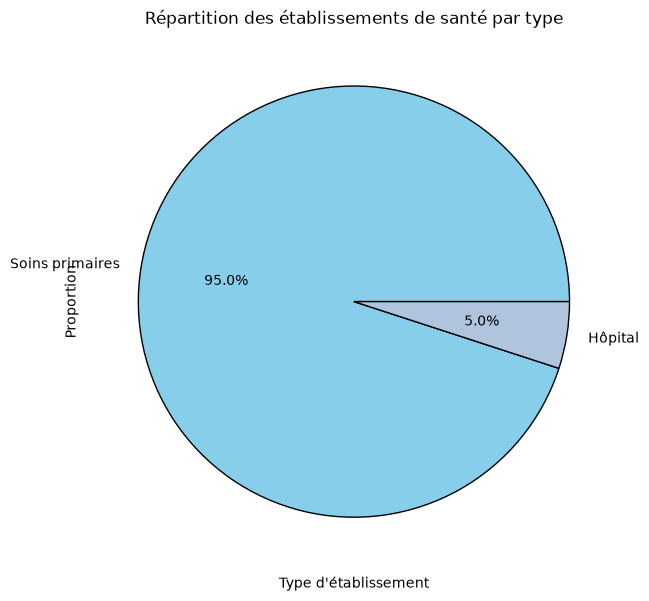

In [64]:
# 1. Quelle est la repartition globale des etablissements de sante entre soins primaires et reseau hospitalier ?
data_type = df['Type_établissement'].value_counts()
plt.figure(figsize=(7, 7))
plt.pie(data_type, labels=data_type.index, autopct='%1.1f%%', colors=['skyblue', 'lightsteelblue'], wedgeprops={'edgecolor': 'black'})
plt.title("Répartition des établissements de santé par type")
plt.xlabel("Type d'établissement")
plt.ylabel("Proportion")
plt.grid(True)
plt.show()

L'offre publique de santé au Maroc repose très majoritairement sur les structures de soins primaires, qui représentent 95,0 % du total national (soit 3 224 établissements). Le réseau hospitalier public constitue quant à lui 5,0 % de l'ensemble avec 170 hôpitaux. Cette organisation illustre une pyramide sanitaire où la première ligne de contact assure l'essentiel de la couverture de proximité.

### Question 2 : Répartition des établissements de santé par région
- Objectif de la cellule : Identifier les disparités régionales dans le nombre total d'infrastructures sanitaires.
- Action du code : Agrégation du nombre d'établissements par région et affichage sous forme de diagramme en barres.
- Résultat attendu : Classement ordonné des 12 régions selon leur volume total d'infrastructures.

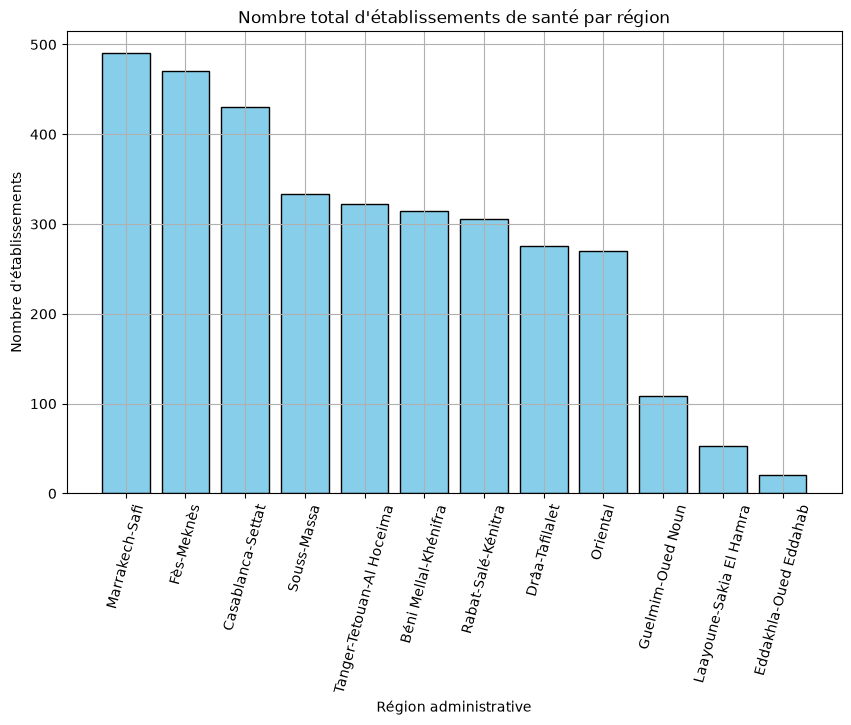

In [65]:
# 2. Comment le nombre total d'etablissements de sante se repartit-il entre les 12 regions du Maroc ?
data_region = df['Région'].value_counts()
plt.figure(figsize=(10, 6))
plt.bar(data_region.index, data_region.values, color='skyblue', edgecolor='black')
plt.title("Nombre total d'établissements de santé par région")
plt.xlabel("Région administrative")
plt.ylabel("Nombre d'établissements")
plt.xticks(rotation=75)
plt.grid(True)
plt.show()

Une forte concentration géographique caractérise le réseau sanitaire national. Les trois premières régions totalisent à elles seules près de 41,0 % des infrastructures : Marrakech-Safi en tête avec 490 établissements (14,4 %), suivie de Fès-Meknès avec 471 structures (13,9 %) et de Casablanca-Settat avec 430 établissements (12,7 %). À l'opposé, les régions sahariennes affichent des volumes nettement plus restreints, notamment Guelmim-Oued Noun (108), Laâyoune-Sakia El Hamra (53) et Dakhla-Oued Ed-Dahab (20 structures).

### Question 3 : Les dix délégations provinciales les plus dotées
- Objectif de la cellule : Déterminer quelles provinces disposent du volume le plus élevé d'infrastructures de santé.
- Action du code : Extraction et affichage du top 10 des délégations provinciales.
- Résultat attendu : Graphique en barres mettant en évidence les délégations leaders.

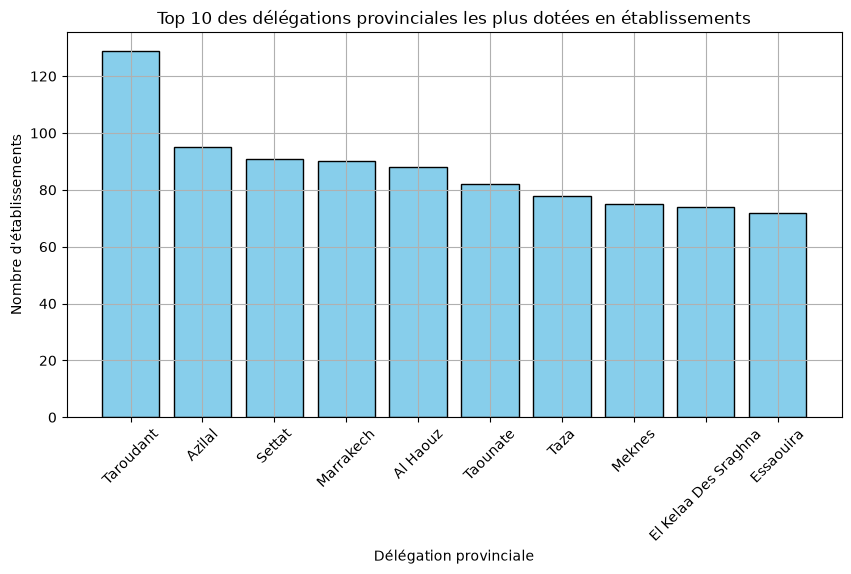

In [66]:
# 3. Quelles sont les dix delegations provinciales les plus dotees en etablissements de sante ?
data_top10 = df['Délégation'].value_counts().head(10)
plt.figure(figsize=(10, 5))
plt.bar(data_top10.index, data_top10.values, color='skyblue', edgecolor='black')
plt.title("Top 10 des délégations provinciales les plus dotées en établissements")
plt.xlabel("Délégation provinciale")
plt.ylabel("Nombre d'établissements")
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

La délégation de Taroudant arrive largement au premier rang national avec 129 établissements de santé. Elle est suivie par Azilal (95 structures), Settat (91), Marrakech (90), Al Haouz (88), Taounate (82) et Taza (78). Ces provinces correspondent principalement à de vastes territoires ruraux ou montagneux caractérisés par un habitat dispersé, nécessitant la multiplication de petits points de contact sanitaire de proximité.

### Question 4 : Les dix délégations provinciales les moins dotées
- Objectif de la cellule : Repérer les territoires disposant des effectifs les plus faibles d'infrastructures de santé.
- Action du code : Extraction et affichage des 10 délégations ayant le plus petit nombre d'établissements.
- Résultat attendu : Graphique en barres identifiant les provinces à faible effectif de structures.

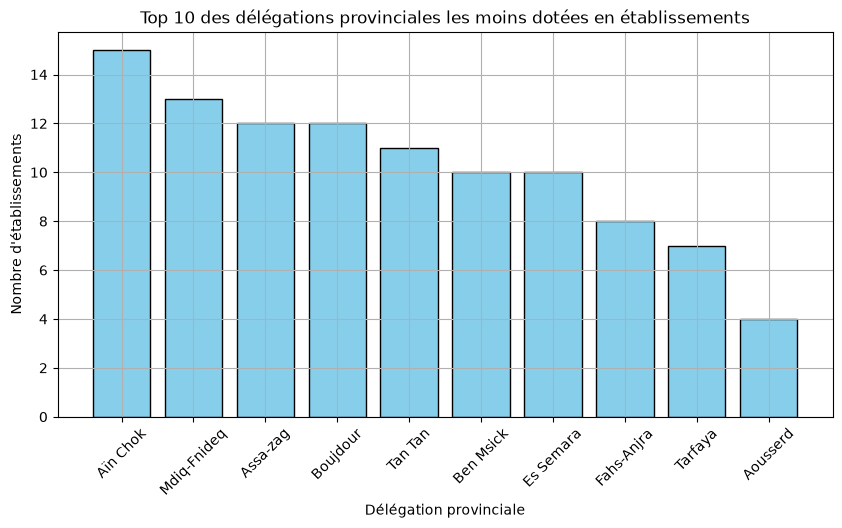

In [67]:
# 4. Quelles sont les dix delegations provinciales les moins dotees en etablissements de sante ?
data_bottom10 = df['Délégation'].value_counts().tail(10)
plt.figure(figsize=(10, 5))
plt.bar(data_bottom10.index, data_bottom10.values, color='skyblue', edgecolor='black')
plt.title("Top 10 des délégations provinciales les moins dotées en établissements")
plt.xlabel("Délégation provinciale")
plt.ylabel("Nombre d'établissements")
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

Les délégations les moins dotées se composent de deux profils bien distincts : d'une part les provinces sahariennes à faible densité comme Aousserd (4 établissements), Tarfaya (7), Es-Semara (10), Tan-Tan (11) et Boujdour (12) ; d'autre part des préfectures urbaines très denses et compactes comme Fahs-Anjra (8), Ben M'sick (10) ou Al Fida-Mers Sultan (15). Dans ce second cas, la faible quantité de structures est compensée par une surface restreinte et la proximité d'hôpitaux de recours.

### Question 5 : Répartition de l'offre selon le milieu d'implantation
- Objectif de la cellule : Comparer la part globale des infrastructures entre zones rurales et zones urbaines.
- Action du code : Décompte des établissements par milieu et affichage en barres.
- Résultat attendu : Comparaison directe entre milieu rural et milieu urbain.

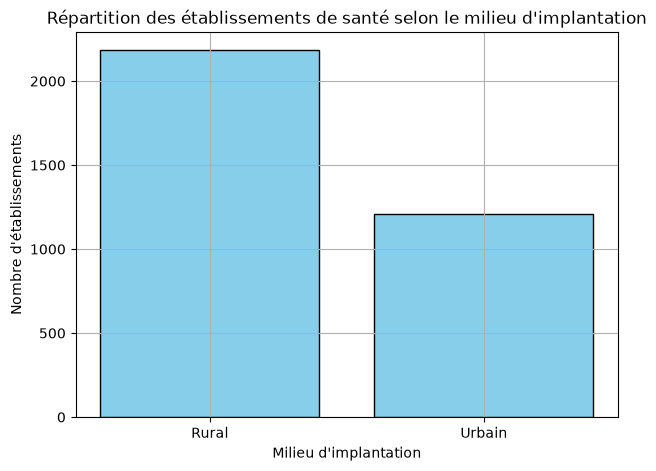

In [68]:
# 5. Quelle est la repartition des infrastructures de sante entre le milieu rural et le milieu urbain ?
data_milieu = df['Milieu'].value_counts()
plt.figure(figsize=(7, 5))
plt.bar(data_milieu.index, data_milieu.values, color='skyblue', edgecolor='black')
plt.title("Répartition des établissements de santé selon le milieu d'implantation")
plt.xlabel("Milieu d'implantation")
plt.ylabel("Nombre d'établissements")
plt.grid(True)
plt.show()

Le milieu rural concentre près des deux tiers de l'offre nationale avec 2 183 structures (soit 64,3 % du total), contre 1 211 structures en milieu urbain (soit 35,7 %). Cette prédominance rurale traduit la volonté de mailler un territoire rural étendu afin de réduire les distances d'accès aux soins de premier niveau pour les populations éloignées des centres urbains.

### Question 6 : Répartition des principales catégories d'établissements
- Objectif de la cellule : Identifier les catégories techniques de soins les plus fréquemment déployées.
- Action du code : Sélection des 6 catégories les plus courantes et visualisation en barres.
- Résultat attendu : Mise en valeur des structures dominantes du réseau.

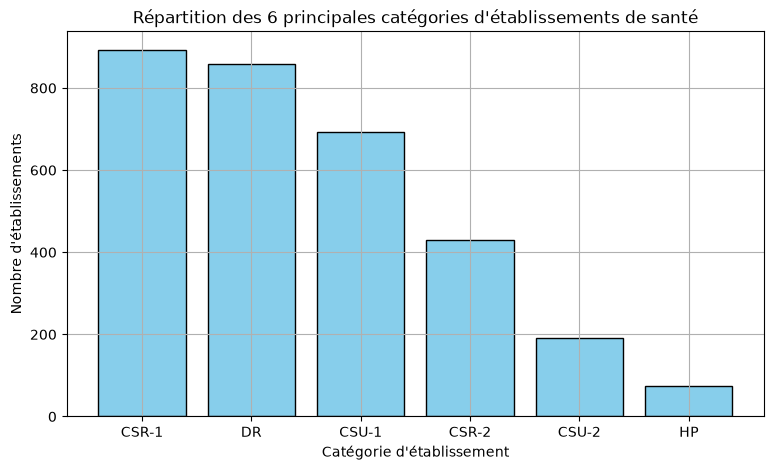

In [69]:
# 6. Quelles sont les principales categories d'etablissements de sante au Maroc ?
data_cat = df['Catégorie'].value_counts().head(6)
plt.figure(figsize=(9, 5))
plt.bar(data_cat.index, data_cat.values, color='skyblue', edgecolor='black')
plt.title("Répartition des 6 principales catégories d'établissements de santé")
plt.xlabel("Catégorie d'établissement")
plt.ylabel("Nombre d'établissements")
plt.grid(True)
plt.show()

L'offre de santé est portée par trois piliers majeurs : les centres de santé ruraux de niveau 1 (CSR-1) avec 893 unités (26,3 %), les dispensaires ruraux (DR) avec 859 unités (25,3 %) et les centres de santé urbains de niveau 1 (CSU-1) avec 692 structures (20,4 %). Les centres de santé ruraux de niveau 2 (CSR-2, intégrant souvent des maternités) comptent 431 structures, tandis que les hôpitaux provinciaux (HP) totalisent 74 établissements.

### Question 7 : Distribution statistique de la dotation par délégation
- Objectif de la cellule : Observer la dispersion et la forme de la distribution du nombre d'établissements par province.
- Action du code : Groupement par délégation provinciale et tracé d'un histogramme des effectifs.
- Résultat attendu : Histogramme illustrant la distribution et l'asymétrie de la dotation provinciale.

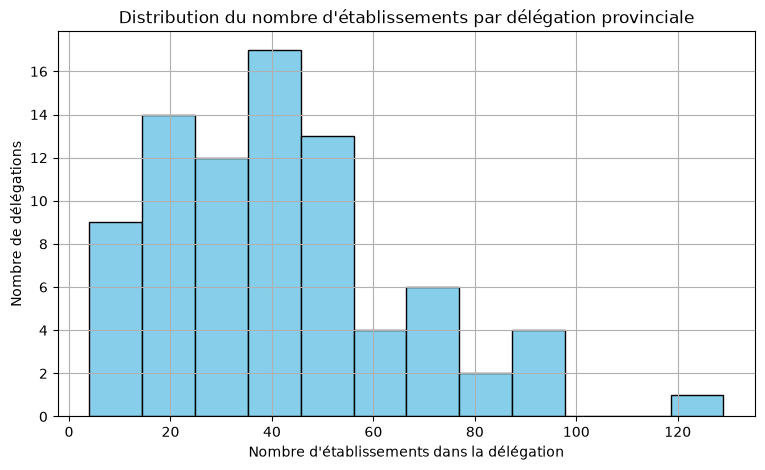

In [70]:
# 7. Quelle est la distribution de la dotation provinciale en etablissements de sante ?
etab_par_deleg = df.groupby('Délégation').size()
plt.figure(figsize=(9, 5))
plt.hist(etab_par_deleg, bins=12, color='skyblue', edgecolor='black')
plt.title("Distribution du nombre d'établissements par délégation provinciale")
plt.xlabel("Nombre d'établissements dans la délégation")
plt.ylabel("Nombre de délégations")
plt.grid(True)
plt.show()

La distribution présente une asymétrie positive nette à droite. La médiane s'établit à 37 établissements par province, la majorité des 82 délégations (la moitié centrale comprise entre 23 et 53 structures) se regroupant en deçà de 50 structures. Une minorité de grandes provinces rurales étendues (notamment Taroudant, Azilal et Settat) forment la queue de distribution en dépassant 90 établissements.

### Question 8 : Proportion du milieu rural selon les régions
- Objectif de la cellule : Mesurer le profil rural ou urbain de chaque région administrative.
- Action du code : Calcul du pourcentage d'établissements ruraux par région et tracé d'un graphique en barres.
- Résultat attendu : Classement des 12 régions selon leur taux de ruralité sanitaire.

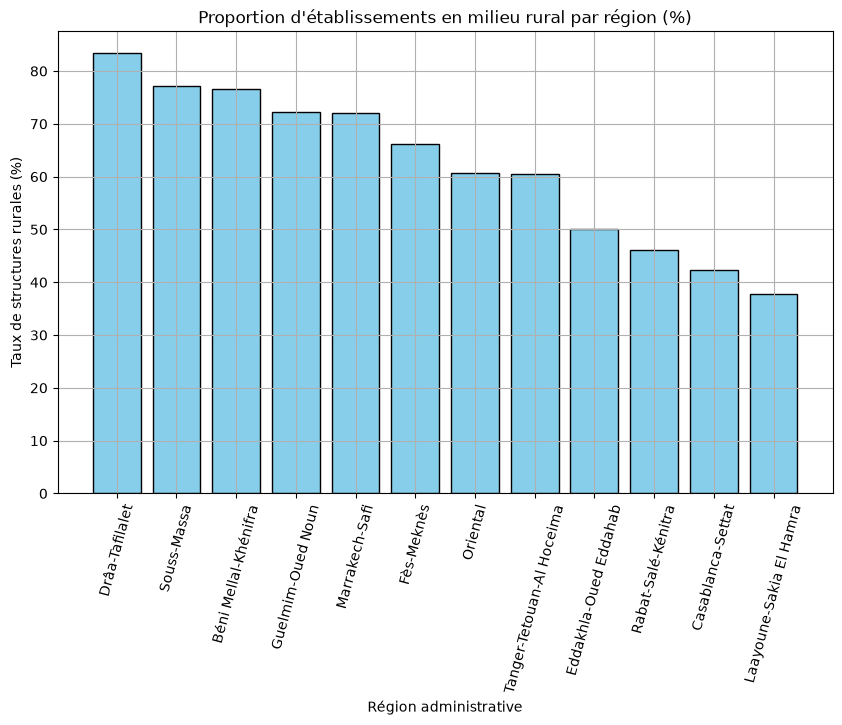

In [71]:
# 8. Quelle est la proportion d'etablissements en milieu rural au sein de chaque region ?
taux_rural_region = df.groupby('Région')['Milieu'].apply(lambda x: (x == 'Rural').mean() * 100).sort_values(ascending=False)
plt.figure(figsize=(10, 6))
plt.bar(taux_rural_region.index, taux_rural_region.values, color='skyblue', edgecolor='black')
plt.title("Proportion d'établissements en milieu rural par région (%)")
plt.xlabel("Région administrative")
plt.ylabel("Taux de structures rurales (%)")
plt.xticks(rotation=75)
plt.grid(True)
plt.show()

Les disparités territoriales se manifestent nettement dans l'orientation de l'offre régionale. Les régions de Drâa-Tafilalet (83,3 %), Souss-Massa (77,2 %), Béni Mellal-Khénifra (76,5 %) et Marrakech-Safi (72,0 %) présentent une offre très largement rurale, dictée par la géographie locale. À l'inverse, seules trois régions comptent une majorité d'établissements urbains : Rabat-Salé-Kénitra (53,9 % urbain), Casablanca-Settat (57,7 % urbain) et Laâyoune-Sakia El Hamra (62,3 % urbain).

### Question 9 : Répartition territoriale de l'offre hospitalière
- Objectif de la cellule : Analyser la localisation des 170 hôpitaux publics entre les régions.
- Action du code : Filtrage des établissements de type Hôpital, comptage par région et tracé d'un diagramme en barres.
- Résultat attendu : Classement des régions selon leur dotation hospitalière.

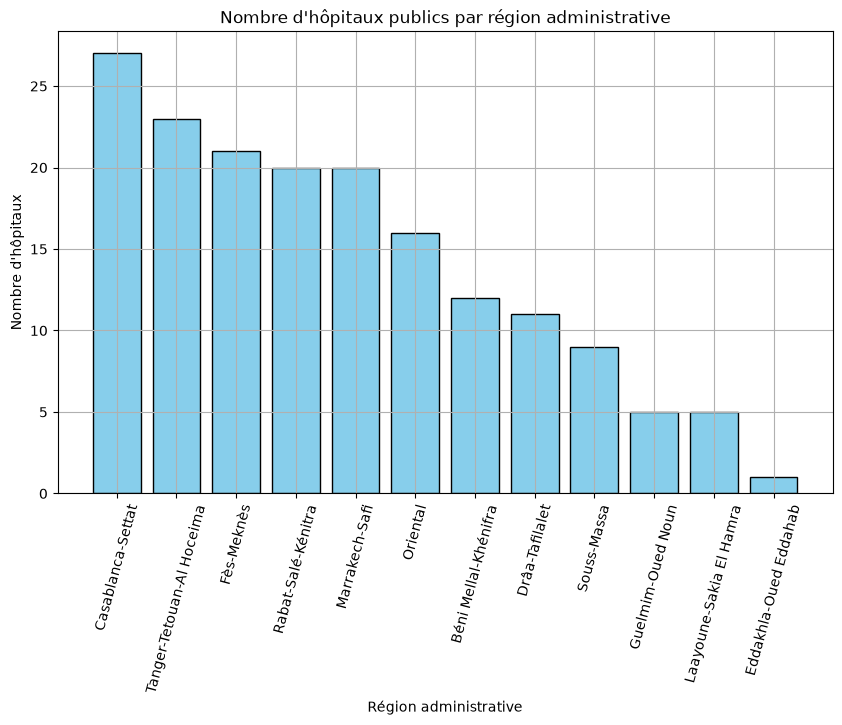

In [72]:
# 9. Comment l'offre hospitaliere publique est-elle repartie a travers les regions du Royaume ?
hopitaux_region = df[df['Type_établissement'] == 'Hôpital']['Région'].value_counts()
plt.figure(figsize=(10, 6))
plt.bar(hopitaux_region.index, hopitaux_region.values, color='skyblue', edgecolor='black')
plt.title("Nombre d'hôpitaux publics par région administrative")
plt.xlabel("Région administrative")
plt.ylabel("Nombre d'hôpitaux")
plt.xticks(rotation=75)
plt.grid(True)
plt.show()

L'armature hospitalière publique est fortement corrélée aux grands centres démographiques et économiques. Casablanca-Settat concentre le plus grand nombre d'hôpitaux avec 27 établissements, suivie de Tanger-Tétouan-Al Hoceima (23 hôpitaux), Fès-Meknès (21 hôpitaux), Rabat-Salé-Kénitra (20) et Marrakech-Safi (20). Les régions du Sud disposent d'un réseau hospitalier plus resserré (Guelmim-Oued Noun et Laâyoune-Sakia El Hamra comptant chacune 5 hôpitaux, et Dakhla-Oued Ed-Dahab 1 hôpital régional).

### Question 10 : Courbe de concentration de l'offre sanitaire par délégation
- Objectif de la cellule : Évaluer le degré de concentration cumulée des établissements parmi les délégations.
- Action du code : Calcul du pourcentage cumulé des structures triées par délégation et tracé d'une courbe avec marqueurs.
- Résultat attendu : Courbe de concentration illustrant l'inégalité de répartition provinciale.

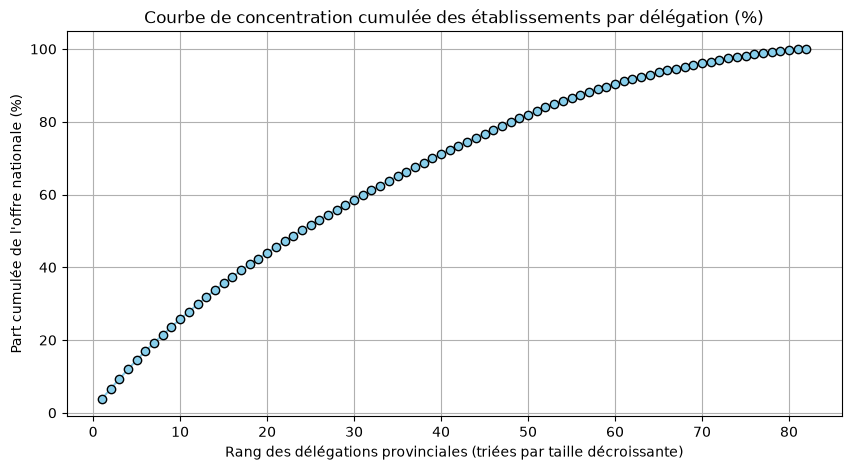

In [73]:
# 10. Quel est le degre de concentration cumulee des etablissements selon le rang des delegations ?
cumul_etab = df.groupby('Délégation').size().sort_values(ascending=False).cumsum() / len(df) * 100
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(cumul_etab) + 1), cumul_etab.values, marker='o', color='skyblue', markeredgecolor='black')
plt.title("Courbe de concentration cumulée des établissements par délégation (%)")
plt.xlabel("Rang des délégations provinciales (triées par taille décroissante)")
plt.ylabel("Part cumulée de l'offre nationale (%)")
plt.grid(True)
plt.show()

La courbe de concentration montre que les 20 premières délégations provinciales (soit moins d'un quart des 82 délégations) concentrent près de 47,0 % de l'offre nationale totale. Cette concentration reflète la structure démographique et géographique du pays, où un nombre restreint de provinces très étendues ou très peuplées abrite une part substantielle des infrastructures de soins.

## Section 4 : Visualisations Complémentaires Interactives (Plotly et Seaborn)

Pour enrichir l'exploration territoriale et tirer parti de l'interactivité moderne, cette section mobilise **Plotly Express** pour l'inspection dynamique des données provinciales et **Seaborn** pour l'analyse bivariée approfondie.

### Classement interactif du Top 15 des délégations (Plotly Express)
- Objectif de la cellule : Permettre un survol interactif des délégations provinciales les plus fournies.
- Action du code : Préparation du Top 15 et génération d'un diagramme en barres interactif avec `px.bar()`.
- Résultat attendu : Graphique interactif avec infobulles détaillées.

In [74]:
top15_deleg = df['Délégation'].value_counts().head(15).reset_index()
top15_deleg.columns = ['Délégation', 'Nombre_Etablissements']
fig_deleg = px.bar(top15_deleg, x='Délégation', y='Nombre_Etablissements', 
                   title="Top 15 des délégations provinciales (Plotly Interactif)", 
                   text='Nombre_Etablissements', 
                   color='Nombre_Etablissements', 
                   color_continuous_scale='Blues')
fig_deleg.update_layout(xaxis_title="Délégation provinciale", yaxis_title="Nombre d'établissements")
fig_deleg.show()

Ce graphique interactif confirme le leadership de Taroudant avec 129 établissements, marquant un écart net avec la seconde province Azilal (95 structures). L'interactivité permet d'explorer précisément les valeurs de chaque territoire.

### Diagramme interactif en anneau : Milieu Rural vs Urbain (Plotly Express)
- Objectif de la cellule : Visualiser la proportion nationale rural/urbain avec un graphique en anneau moderne.
- Action du code : Agrégation des effectifs par milieu et tracé d'un diagramme circulaire troué avec `px.pie()`.
- Résultat attendu : Diagramme interactif affichant les pourcentages exacts au survol.

In [75]:
milieu_summary = df['Milieu'].value_counts().reset_index()
milieu_summary.columns = ['Milieu', 'Nombre']
fig_milieu = px.pie(milieu_summary, names='Milieu', values='Nombre', hole=0.45, 
                    title="Répartition nationale Rural vs Urbain (Plotly Express)", 
                    color_discrete_sequence=['#4682B4', '#87CEEB'])
fig_milieu.show()

La visualisation interactive met en relief la part prépondérante du milieu rural (64,3 %, 2 183 établissements) par rapport au milieu urbain (35,7 %, 1 211 structures).

### Relation entre nombre de communes et nombre d'établissements par délégation (Plotly Express)
- Objectif de la cellule : Examiner si la dotation d'une délégation découle directement du nombre de communes qu'elle englobe.
- Action du code : Agrégation du nombre de communes distinctes et d'établissements par délégation, et tracé avec `px.scatter()`.
- Résultat attendu : Nuage de points interactif révélant la corrélation positive entre communes et infrastructures.

In [76]:
communes_etab = df.groupby('Délégation').agg(
    Nombre_Communes=('Commune', 'nunique'),
    Nombre_Etablissements=('Nom_établissement', 'count'),
    Région=('Région', 'first')
).reset_index()
fig_scatter = px.scatter(communes_etab, x='Nombre_Communes', y='Nombre_Etablissements', 
                         color='Région', hover_name='Délégation',
                         title="Relation entre nombre de communes et nombre d'établissements par délégation (Plotly Express)")
fig_scatter.update_layout(xaxis_title="Nombre de communes par délégation", yaxis_title="Nombre d'établissements de santé")
fig_scatter.show()

Une très forte corrélation positive apparaît entre le nombre de communes d'une province et son volume d'établissements. Cela confirme que l'implantation des centres de santé de premier recours suit la logique de maillage d'au moins une structure par commune rurale.

### Décomposition croisée Région × Milieu (Seaborn)
- Objectif de la cellule : Comparer visuellement la composition rurale et urbaine de chacune des 12 régions.
- Action du code : Utilisation de `sns.countplot()` avec paramètre `hue='Milieu'`.
- Résultat attendu : Diagramme à barres horizontales groupées illustrant le profil territorial régional.

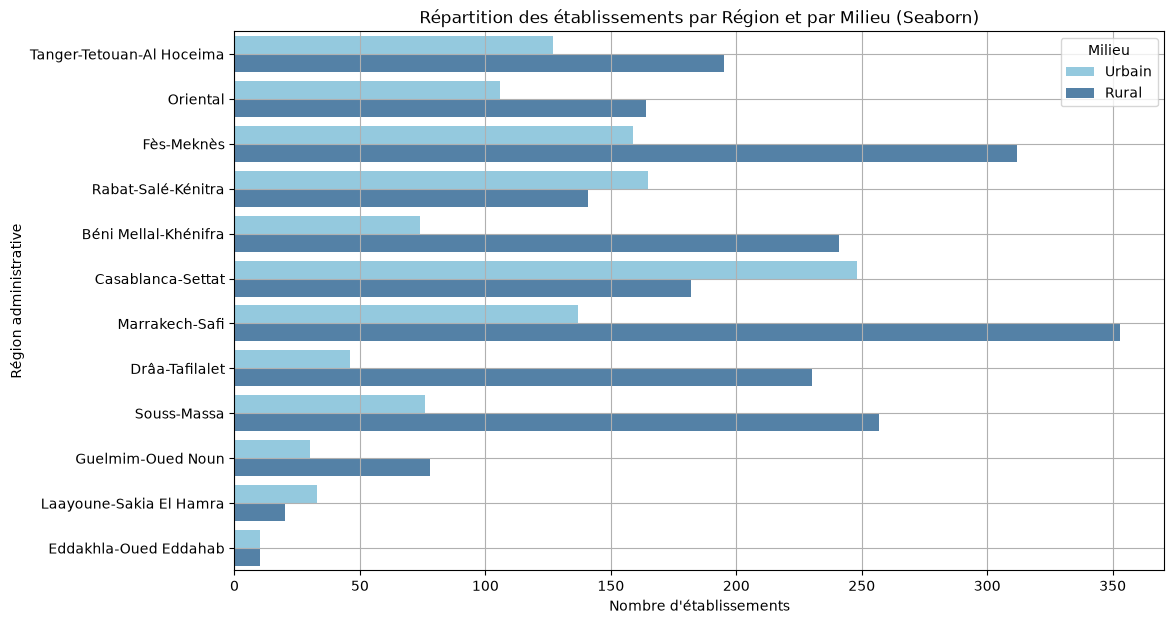

In [77]:
plt.figure(figsize=(12, 7))
sns.countplot(data=df, y='Région', hue='Milieu', palette=['skyblue', 'steelblue'])
plt.title("Répartition des établissements par Région et par Milieu (Seaborn)")
plt.xlabel("Nombre d'établissements")
plt.ylabel("Région administrative")
plt.grid(True)
plt.show()

Ce graphique Seaborn met en évidence la dualité territoriale : les régions montagneuses et rurales comme Drâa-Tafilalet, Souss-Massa et Béni Mellal-Khénifra comptent une écrasante majorité de structures rurales, tandis que Casablanca-Settat et Rabat-Salé-Kénitra sont dominées par le milieu urbain.

## Section 5 : Synthèse des Résultats et Conclusion

### Tableau récapitulatif des constats clés

| Indicateur clé | Constat chiffré | Interprétation territoriale |
| :--- | :--- | :--- |
| **Volume national** | 3 394 établissements publics | Réseau dense couvrant l'ensemble des 12 régions et 82 délégations |
| **Pyramide des soins** | 95,0 % soins primaires (3 224) vs 5,0 % hôpitaux (170) | Priorité donnée au premier contact et à la médecine de proximité |
| **Milieu d'implantation** | 64,3 % en milieu rural (2 183) vs 35,7 % en milieu urbain (1 211) | Forte présence rurale dictée par la dispersion géographique |
| **Top 3 des régions** | Marrakech-Safi (490), Fès-Meknès (471), Casablanca-Settat (430) | Concentration de 41,0 % de l'offre nationale sur 3 régions |
| **Régions sahariennes** | Dakhla-Oued Ed-Dahab (20), Laâyoune-Sakia El Hamra (53) | Effectifs restreints adaptés à de faibles densités démographiques |
| **Province leader** | Taroudant (129 établissements) | Vaste province rurale et montagneuse nécessitant un maillage étendu |
| **Délégations compactes** | Aousserd (4), Tarfaya (7), Fahs-Anjra (8), Ben M'sick (10) | Territoires sahariens très peu peuplés ou préfectures urbaines restreintes |
| **Facteur explicatif majeur** | Forte corrélation positive entre nombre de communes et d'établissements | Règle d'aménagement prévoyant au minimum un centre de santé par commune |

---

### Conclusion sur la problématique

À la question centrale posée :
> **« La répartition des établissements de santé au Maroc est-elle équitable entre les différentes régions, délégations et communes, et existe-t-il des disparités dans l’accès aux infrastructures de santé selon les territoires ? »**

Notre analyse permet de conclure que :

1. **L'équité arithmétique n'est pas uniforme :** Il existe de très forts écarts de volume brut entre les régions et entre les provinces. Toutefois, ces écarts ne traduisent pas nécessairement une iniquité arbitraire mais répondent à des contraintes territoriales majeures.
2. **La contrainte géographique impose la dispersion :** Dans les provinces étendues, montagneuses et à habitat dispersé (comme Taroudant avec 129 structures et Azilal avec 95), le ministère a multiplié les dispensaires et centres de santé ruraux pour limiter le temps d'accès physique aux soins de premier niveau.
3. **La concentration hospitalière :** Si les soins primaires sont largement décentralisés en zone rurale (64,3 %), l'offre hospitalière (170 établissements) demeure très concentrée dans les grands pôles urbains et chefs-lieux régionaux (notamment Casablanca-Settat avec 27 hôpitaux).

### Recommandations pour la planification sanitaire

- **Renforcement qualitatif des structures rurales :** Les dispensaires ruraux (DR) et centres de santé de niveau 1 (CSR-1) constituent plus de 50 % de l'offre nationale. Leur dotation en personnel médical permanent et en équipements d'urgence est indispensable pour désengorger les hôpitaux urbains.
- **Développement des hôpitaux de proximité (HPr) :** Densifier le maillage intermédiaire entre le dispensaire rural et le centre hospitalier provincial afin d'assurer les urgences et la santé maternelle dans les territoires isolés.
- **Intégration du temps d'accès dans la carte sanitaire :** Compléter la planification basée sur les découpages communaux par des indicateurs d'accessibilité isochrone (temps de trajet effectif en minutes).